# Лабораторная работа 1. Анализ научных статей с помощью графов

## Пункт 1. Выбор темы

> Выбрать тематику научных публикаций, любую область знаний, например, machine learning или artificial intelligence. Лучше брать что-то более узкое и интересное вам.

**Тема: Entity Resolution / Record Linkage / Fuzzy matching.** Изучаем методы, которые помогают понять, что разные записи описывают один и тот же объект. Например, один адрес может быть записан несколькими способами.

## Подготовка

In [43]:
%matplotlib inline

import re
import random
from collections import Counter, defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from spacy.lang.en.stop_words import STOP_WORDS
from IPython.display import display
from networkx.algorithms import community as nx_comm

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seqblue", ["#cde2fb", "#2a78d6", "#0d366b"])
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2,
    "axes.titlecolor": INK,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "font.size": 10,
    "figure.dpi": 110,
})

## Пункт 2. Сбор данных

> Скачать с https://arxiv.org/ данные о научных публикациях по выбранной тематике. Выгрузить названия, авторов и аннотации статей. Скачивать через api https://info.arxiv.org/help/api/user-manual.html. Не менее 300 публикаций. Публикации должны быть не старше 2020 года.

Собраны **477 статей за 2020–2026 годы**: названия, авторы, аннотации и даты.

Использованы запросы `entity resolution`, `entity matching`, `record linkage`, `fuzzy matching`, `approximate string matching`.

In [44]:
df = pd.read_csv("data/papers.csv", dtype=str)
required_columns = ["arxiv_id", "title", "authors", "abstract", "published"]
assert len(df) >= 300, "Для задания нужно не менее 300 публикаций"
assert df[required_columns].notna().all().all(), "В обязательных полях есть пропуски"
assert df[required_columns].apply(lambda s: s.str.strip().ne("")).all().all()
assert df["arxiv_id"].is_unique, "В корпусе есть повторяющиеся arXiv id"
publication_dates = pd.to_datetime(df["published"], utc=True, errors="raise")
assert publication_dates.ge(pd.Timestamp("2020-01-01", tz="UTC")).all()
assert publication_dates.le(pd.Timestamp.now(tz="UTC")).all()

df["year"] = df["published"].str[:4].astype(int)
df["n_authors"] = df["authors"].str.split(";").str.len()

print(f"Всего публикаций: {len(df)}")
print(f"Период: {df['published'].min()[:10]} ... {df['published'].max()[:10]}")
display(df[["arxiv_id", "title", "year", "n_authors", "primary_category"]].head(8))

Всего публикаций: 477
Период: 2020-01-07 ... 2026-10-13


,arxiv_id,title,year,n_authors,primary_category
0,2001.01895,Machine-learning classifiers for logographic name matching in public health applications: approaches for i...,2020,9,cs.IR
1,2001.01961,Complexity Issues of String to Graph Approximate Matching,2020,3,cs.DS
2,2001.09233,Case Study: Predictive Fairness to Reduce Misdemeanor Recidivism Through Social Service Interventions,2020,6,cs.CY
3,2002.05607,Pre-Training for Query Rewriting in A Spoken Language Understanding System,2020,5,cs.CL
4,2002.09119,Bayesian Causal Inference with Bipartite Record Linkage,2020,3,stat.ME
5,2002.09361,Crowdsourced Collective Entity Resolution with Relational Match Propagation,2020,4,cs.DB
6,2002.12459,Fast Join Project Query Evaluation using Matrix Multiplication,2020,3,cs.DB
7,2003.00060,Automatically matching topographical measurements of cartridge cases using a record linkage framework,2020,2,stat.AP


## Пункт 3. Обзор данных

> Провести разведочных анализ данных собранного корпуса текстов. Построить визуализации, в частности для проверки закона Ципфа.

Посмотрим, как статьи распределены по годам, авторам и темам, насколько длинные у них аннотации и какие слова встречаются чаще.

In [45]:
all_authors = Counter(a.strip() for s in df["authors"] for a in s.split(";") if a.strip())

print(f"Уникальных авторов: {len(all_authors)}")
print(f"Среднее число авторов на статью: {df['n_authors'].mean():.2f}")
print(f"Медианная длина аннотации: {df['abstract'].str.split().str.len().median():.0f} слов")
print(f"Самая частая первичная категория: {df['primary_category'].mode()[0]}")

Уникальных авторов: 1766
Среднее число авторов на статью: 4.35
Медианная длина аннотации: 193 слов
Самая частая первичная категория: cs.CL


### Пункт 3. Графики по данным

> Провести разведочных анализ данных собранного корпуса текстов. Построить визуализации, в частности для проверки закона Ципфа.

Строим распределения по годам, авторам, категориям и длине аннотаций.

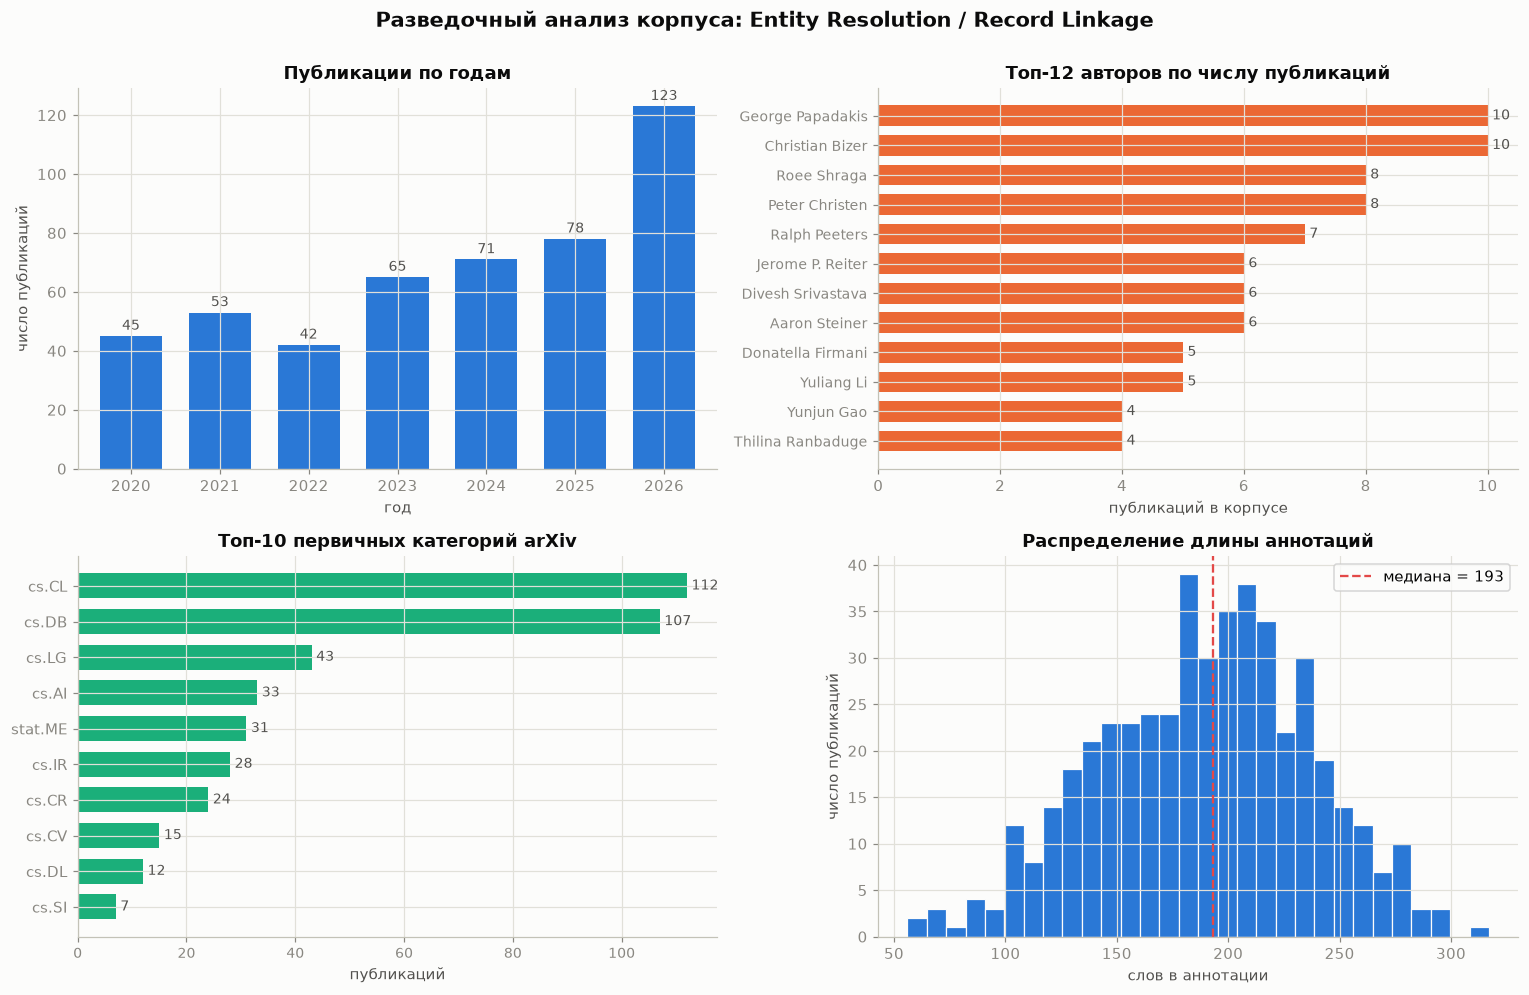

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

ax = axes[0, 0]
by_year = df["year"].value_counts().sort_index()
by_year.plot(kind="bar", ax=ax, color=CAT[0], width=0.7)
ax.bar_label(ax.containers[0], padding=2, fontsize=9, color=INK2)
ax.set_title("Публикации по годам")
ax.set_xlabel("год")
ax.set_ylabel("число публикаций")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

ax = axes[0, 1]
top_authors = pd.Series(all_authors).sort_values(ascending=False).head(12)[::-1]
ax.barh(top_authors.index, top_authors.values, color=CAT[1], height=0.7)
ax.bar_label(ax.containers[0], padding=3, fontsize=9, color=INK2)
ax.set_title("Топ-12 авторов по числу публикаций")
ax.set_xlabel("публикаций в корпусе")
ax.tick_params(axis="y", labelsize=9)

ax = axes[1, 0]
cats = df["primary_category"].value_counts().head(10)[::-1]
ax.barh(cats.index, cats.values, color=CAT[2], height=0.7)
ax.bar_label(ax.containers[0], padding=3, fontsize=9, color=INK2)
ax.set_title("Топ-10 первичных категорий arXiv")
ax.set_xlabel("публикаций")
ax.tick_params(axis="x", labelsize=9)

ax = axes[1, 1]
n_words = df["abstract"].str.split().str.len()
ax.hist(n_words, bins=30, color=CAT[0], edgecolor="#fcfcfb", linewidth=0.8)
ax.axvline(n_words.median(), color=CAT[7], linestyle="--", linewidth=1.5,
           label=f"медиана = {n_words.median():.0f}")
ax.set_title("Распределение длины аннотаций")
ax.set_xlabel("слов в аннотации")
ax.set_ylabel("число публикаций")
ax.legend()

fig.suptitle("Разведочный анализ корпуса: Entity Resolution / Record Linkage",
             fontsize=14, fontweight="bold", color=INK, y=1.00)
fig.tight_layout()
plt.show()

### Пункт 3. Частоты слов

> Провести разведочных анализ данных собранного корпуса текстов. Построить визуализации, в частности для проверки закона Ципфа.

**Проверка закона Ципфа.** В текстах небольшое число слов встречается очень часто, а большинство — редко. Проверим, примерно ли вдвое реже встречается слово на втором месте, втрое реже — на третьем и так далее.

Для этого расположим слова по частоте и построим график с логарифмическими осями. При точном совпадении с законом наклон был бы −1. Сравним все слова и слова без частых служебных слов, например `the` и `and`. Наклон оцениваем по первым 200 словам.

Всего токенов: 98,248 | уникальных слов: 7,566


,слово,частота,ранг
0,the,3969,1
1,and,2979,2
2,of,2612,3
3,a,2277,4
4,to,2260,5
5,in,1682,6
6,for,1344,7
7,we,1172,8
8,data,984,9
9,that,972,10


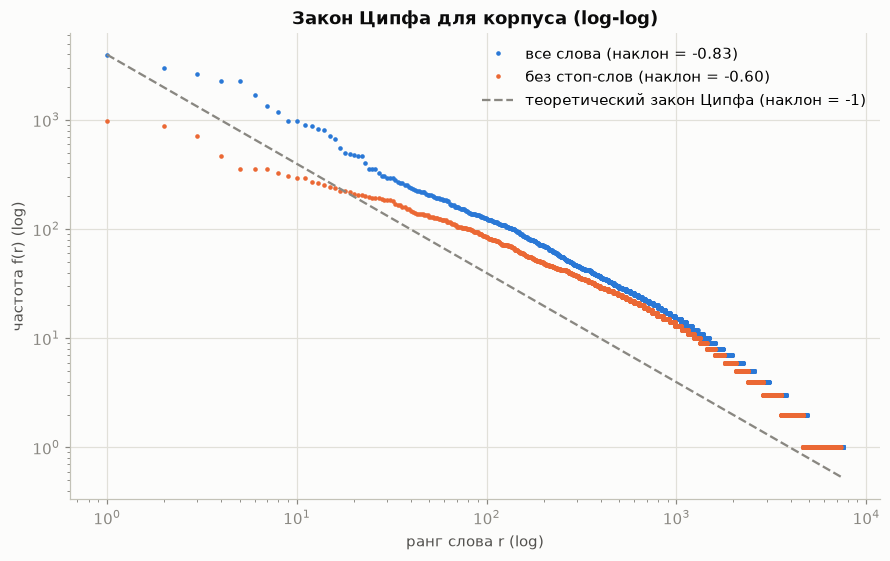

Наклон по всем словам: -0.834 (предсказание Ципфа: -1.0)
Наклон без стоп-слов:  -0.600
R² в log-log координатах (первые 200 рангов): 0.991


In [47]:
STOPWORDS = set(STOP_WORDS)

corpus_text = " ".join((df["title"] + ". " + df["abstract"]).str.lower())
tokens = re.findall(r"\b[a-z]+\b", corpus_text)
freq = Counter(tokens)

top15 = pd.DataFrame(freq.most_common(15), columns=["слово", "частота"])
top15["ранг"] = range(1, 16)
print(f"Всего токенов: {len(tokens):,} | уникальных слов: {len(freq):,}")
display(top15)

freqs_all = np.array([f for _, f in freq.most_common()], dtype=float)
freqs_content = np.array([f for w, f in freq.most_common() if w not in STOPWORDS], dtype=float)


def zipf_slope(freqs, n=200):
    f = freqs[:n]
    r = np.arange(1, len(f) + 1)
    a, _ = np.polyfit(np.log(r), np.log(f), 1)
    return a


fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.loglog(np.arange(1, len(freqs_all) + 1), freqs_all, ".", ms=4, color=CAT[0],
          label=f"все слова (наклон = {zipf_slope(freqs_all):.2f})")
ax.loglog(np.arange(1, len(freqs_content) + 1), freqs_content, ".", ms=4, color=CAT[1],
          label=f"без стоп-слов (наклон = {zipf_slope(freqs_content):.2f})")
r_ref = np.array([1, len(freqs_all)])
ax.loglog(r_ref, freqs_all[0] / r_ref, "--", color=MUTED, linewidth=1.5,
          label="теоретический закон Ципфа (наклон = -1)")
ax.set_title("Закон Ципфа для корпуса (log-log)")
ax.set_xlabel("ранг слова r (log)")
ax.set_ylabel("частота f(r) (log)")
ax.legend(frameon=False)
plt.show()

print(f"Наклон по всем словам: {zipf_slope(freqs_all):.3f} (предсказание Ципфа: -1.0)")
print(f"Наклон без стоп-слов:  {zipf_slope(freqs_content):.3f}")

f_fit = freqs_all[:200]
r_fit = np.arange(1, len(f_fit) + 1)
zipf_coefficients = np.polyfit(np.log(r_fit), np.log(f_fit), 1)
zipf_prediction = np.polyval(zipf_coefficients, np.log(r_fit))
zipf_r2 = 1 - np.sum((np.log(f_fit) - zipf_prediction) ** 2) / np.sum((np.log(f_fit) - np.log(f_fit).mean()) ** 2)
print(f"R² в log-log координатах (первые 200 рангов): {zipf_r2:.3f}")

**Вывод по пункту 3.** В корпусе 477 статей. Их число по годам различается; результат зависит от поисковых запросов. Медианная длина аннотации — 193 слова. По первым 200 словам по частоте наклон равен -0.834, R² = 0.991; без стоп-слов — -0.600. Частые слова встречаются намного чаще редких; совпадение с законом Ципфа приблизительное.

## Пункт 4. Ключевые слова

> Выделить ключевые слова по каждой публикации (используйте названия и аннотации). Обратите внимание, что тут речь идет не только об униграммах, могут быть рассмотрены биграммы, триграммы. Не забывайте делать нормализацию.

Берём название и аннотацию каждой статьи. Приводим слова к начальной форме и выделяем отдельные слова и сочетания из двух или трёх соседних слов. Сочетания не строятся через удалённые слова и знаки препинания.

С помощью **TF-IDF** выбираем до 10 слов и сочетаний, которые лучше отличают статью от остальных. Учитываем термины, встречающиеся минимум в 3 статьях и не более чем в 90% статей. Вложенные сочетания сохраняются: например, `graph` и `knowledge graph` могут быть двумя тегами одной статьи.

In [48]:
EXTRA_STOP = {
    "propose", "proposed", "approach", "method", "methods", "model", "models",
    "result", "results", "show", "showed", "paper", "study", "also", "based", "new", "novel",
    "two", "three", "different", "existing", "well", "many", "however", "thus", "therefore",
    "use", "used", "using", "via", "respectively", "significant", "significantly", "large",
    "small", "high", "low", "task", "problem", "work", "experiment", "experimental",
    "experiments", "evaluation", "evaluate", "performance", "dataset", "datasets",
    "algorithm", "state", "art", "issue", "article", "present", "presented",
    "consider", "focus", "provide", "given", "several", "various", "recent", "previous",
    "efficient", "effective", "important", "real", "world",
}
STOPWORDS_KW = STOPWORDS | EXTRA_STOP

nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
LEMMA_FIX = {"datum": "data"}
UNIGRAM_STOP = {"end", "ground", "truth", "shot"}


def extract_candidates(doc):
    candidates = []
    run = []
    for token in doc:
        lemma = LEMMA_FIX.get(token.lemma_.lower(), token.lemma_.lower())
        if token.text in {"-", "‐", "‑"}:
            continue
        if (token.is_alpha and len(lemma) >= 3 and not token.is_stop
                and lemma not in STOPWORDS_KW and token.pos_ in {"NOUN", "PROPN", "ADJ"}):
            run.append(lemma)
            if token.pos_ in {"NOUN", "PROPN"}:
                for size in range(1, min(3, len(run)) + 1):
                    if size > 1 or lemma not in UNIGRAM_STOP:
                        candidates.append(" ".join(run[-size:]))
        else:
            run = []
    return candidates


def identity_analyzer(candidates):
    return candidates


raw_texts = (df["title"] + ". " + df["abstract"]).tolist()
candidate_lists = [extract_candidates(doc) for doc in nlp.pipe(raw_texts, batch_size=50)]

### Пункт 4. Выбор ключевых слов

> Выделить ключевые слова по каждой публикации (используйте названия и аннотации). Обратите внимание, что тут речь идет не только об униграммах, могут быть рассмотрены биграммы, триграммы. Не забывайте делать нормализацию.

Рассчитываем TF-IDF и выбираем до 10 ключевых слов и сочетаний для каждой статьи.

In [49]:
vectorizer = TfidfVectorizer(analyzer=identity_analyzer, min_df=3, max_df=0.9, sublinear_tf=True)
X = vectorizer.fit_transform(candidate_lists)
feature_names = np.array(vectorizer.get_feature_names_out())

TOP_K = 10


def top_k_keywords(i, k=TOP_K):
    row = X.getrow(i)
    ordered = sorted(zip(row.indices, row.data), key=lambda pair: (-pair[1], feature_names[pair[0]]))
    return [feature_names[j] for j, score in ordered[:k]]


df["keywords"] = [top_k_keywords(i) for i in range(len(df))]

for i in [0, len(df) // 3, len(df) - 1]:
    print(f"\n[{df.loc[i, 'arxiv_id']}] {df.loc[i, 'title']}")
    print("  ключевые слова:", ", ".join(df.loc[i, "keywords"]))


[2001.01895] Machine-learning classifiers for logographic name matching in public health applications: approaches for incorporating phonetic, visual, and keystroke similarity in large-scale probabilistic record linkage
  ключевые слова: probabilistic record, probabilistic record linkage, classifier, power, agreement, regression, similarity, record pair, field, string

[2304.12329] Pre-trained Embeddings for Entity Resolution: An Experimental Analysis [Experiment, Analysis & Benchmark]
  ключевые слова: analysis, blocking, deep learning, embedding, unsupervised matching, deep learning technique, learning technique, embeddings, strength, practitioner

[2610.19048] Pre-Trained Language Models as Zero-Shot Tools for Social Science Research
  ключевые слова: social science, group, science, social, states, united, united states, membership, specific training, inference


### Пункт 4. Частые ключевые слова

> Выделить ключевые слова по каждой публикации (используйте названия и аннотации). Обратите внимание, что тут речь идет не только об униграммах, могут быть рассмотрены биграммы, триграммы. Не забывайте делать нормализацию.

Показываем наиболее распространённые ключевые слова и сочетания.

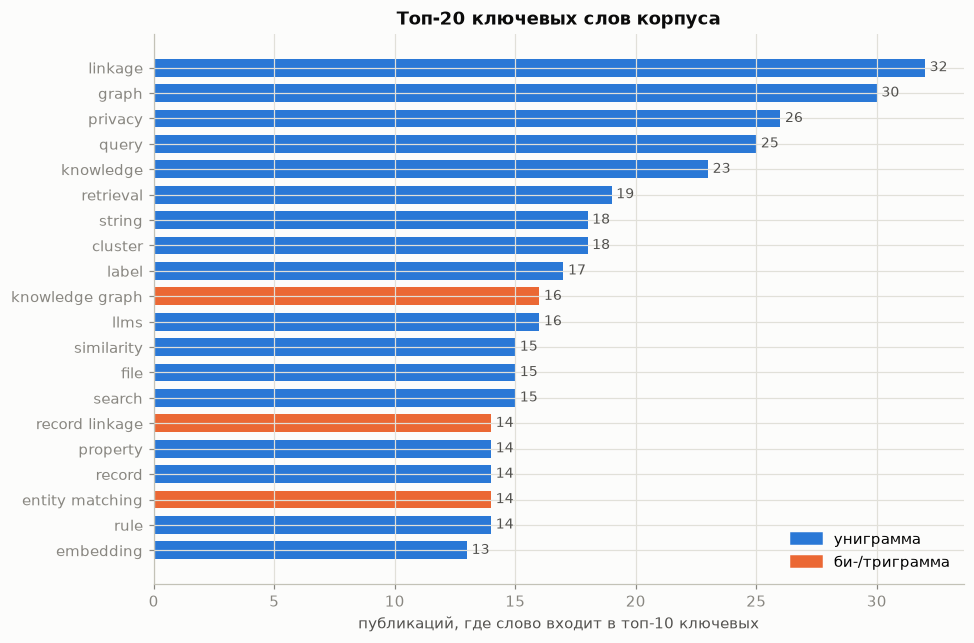

,ключевое слово,публикаций,тип
0,linkage,32,униграмма
1,graph,30,униграмма
2,privacy,26,униграмма
3,query,25,униграмма
4,knowledge,23,униграмма
5,retrieval,19,униграмма
6,string,18,униграмма
7,cluster,18,униграмма
8,label,17,униграмма
9,knowledge graph,16,n-грамма


In [50]:
kw_counter = Counter(kw for kws in df["keywords"] for kw in kws)
top_kw = pd.DataFrame(kw_counter.most_common(20), columns=["ключевое слово", "публикаций"])
top_kw["тип"] = np.where(top_kw["ключевое слово"].str.contains(" "), "n-грамма", "униграмма")

fig, ax = plt.subplots(figsize=(9.5, 6.5))
y = top_kw.iloc[::-1]
colors = [CAT[0] if t == "униграмма" else CAT[1] for t in y["тип"]]
ax.barh(y["ключевое слово"], y["публикаций"], color=colors, height=0.7)
ax.bar_label(ax.containers[0], padding=3, fontsize=9, color=INK2)
ax.set_title("Топ-20 ключевых слов корпуса")
ax.set_xlabel("публикаций, где слово входит в топ-10 ключевых")
ax.legend(handles=[mpatches.Patch(color=CAT[0], label="униграмма"),
                   mpatches.Patch(color=CAT[1], label="би-/триграмма")],
          frameon=False, loc="lower right")
plt.show()

display(top_kw)

### Пункт 4. Проверка обработки текста

> Выделить ключевые слова по каждой публикации (используйте названия и аннотации). Обратите внимание, что тут речь идет не только об униграммах, могут быть рассмотрены биграммы, триграммы. Не забывайте делать нормализацию.

Считаем слова и сочетания разной длины; проверяем, что сочетания строятся из соседних слов.

In [51]:
ngram_counts = Counter(len(kw.split()) for kws in df["keywords"] for kw in kws)
print("Число выбранных терминов по длине:", dict(sorted(ngram_counts.items())))
assert df["keywords"].map(len).gt(0).all(), "Есть статьи без ключевых слов"
assert ngram_counts[2] > 0 and ngram_counts[3] > 0

assert "record linkage" in extract_candidates(nlp("record linkage"))
assert "record linkage" not in extract_candidates(nlp("record and linkage"))
assert "record linkage" not in extract_candidates(nlp("record. Linkage"))
assert "ground truth" in extract_candidates(nlp("ground truth"))

Число выбранных терминов по длине: {1: 3740, 2: 943, 3: 87}


## Пункт 5. Граф ключевых слов

> Построить связи между ключевыми словами на основе их принадлежности публикациям с использованием библиотеки https://networkx.org/.

Каждая точка — ключевое слово, выбранное хотя бы для 5 статей. Два слова соединяются, если они входят в ключевые слова одной статьи. Чем больше таких статей, тем больше вес связи. Для работы с графом используется NetworkX.

In [52]:
KW_MIN_DF = 5
EDGE_MIN_W = 1

kw_docs = defaultdict(list)
for i, kws in enumerate(df["keywords"]):
    for kw in kws:
        kw_docs[kw].append(i)

node_set = {kw for kw, docs in kw_docs.items() if len(docs) >= KW_MIN_DF}

co_occurrence = Counter()
for kws in df["keywords"]:
    for a, b in combinations(sorted(set(kws) & node_set), 2):
        co_occurrence[(a, b)] += 1

G = nx.Graph()
G.add_nodes_from(sorted(node_set))
for (a, b), w in co_occurrence.items():
    if w >= EDGE_MIN_W:
        G.add_edge(a, b, weight=w)
G.remove_nodes_from(list(nx.isolates(G)))

strength = dict(G.degree(weight="weight"))
degree = dict(G.degree())

print(f"Граф ключевых слов: {G.number_of_nodes()} вершин, {G.number_of_edges()} рёбер")
print(f"Плотность: {nx.density(G):.4f}")
print(f"Компонент связности: {nx.number_connected_components(G)}")

kw_stats = (pd.DataFrame({"keyword": list(G.nodes),
                          "degree": [degree[n] for n in G.nodes],
                          "strength": [strength[n] for n in G.nodes],
                          "публикаций": [len(kw_docs[n]) for n in G.nodes]})
            .sort_values("strength", ascending=False)
            .reset_index(drop=True))
display(kw_stats.head(15))

Граф ключевых слов: 240 вершин, 3095 рёбер
Плотность: 0.1079
Компонент связности: 1


,keyword,degree,strength,публикаций
0,linkage,71,133,32
1,graph,78,125,30
2,query,69,96,25
3,knowledge,61,90,23
4,cluster,65,85,18
5,privacy,55,84,26
6,similarity,61,73,15
7,string,45,71,18
8,record linkage,49,69,14
9,retrieval,53,68,19


### Пункт 5. Рисунок графа

> Построить связи между ключевыми словами на основе их принадлежности публикациям с использованием библиотеки https://networkx.org/.

Показываем граф ключевых слов и число связей у его вершин.

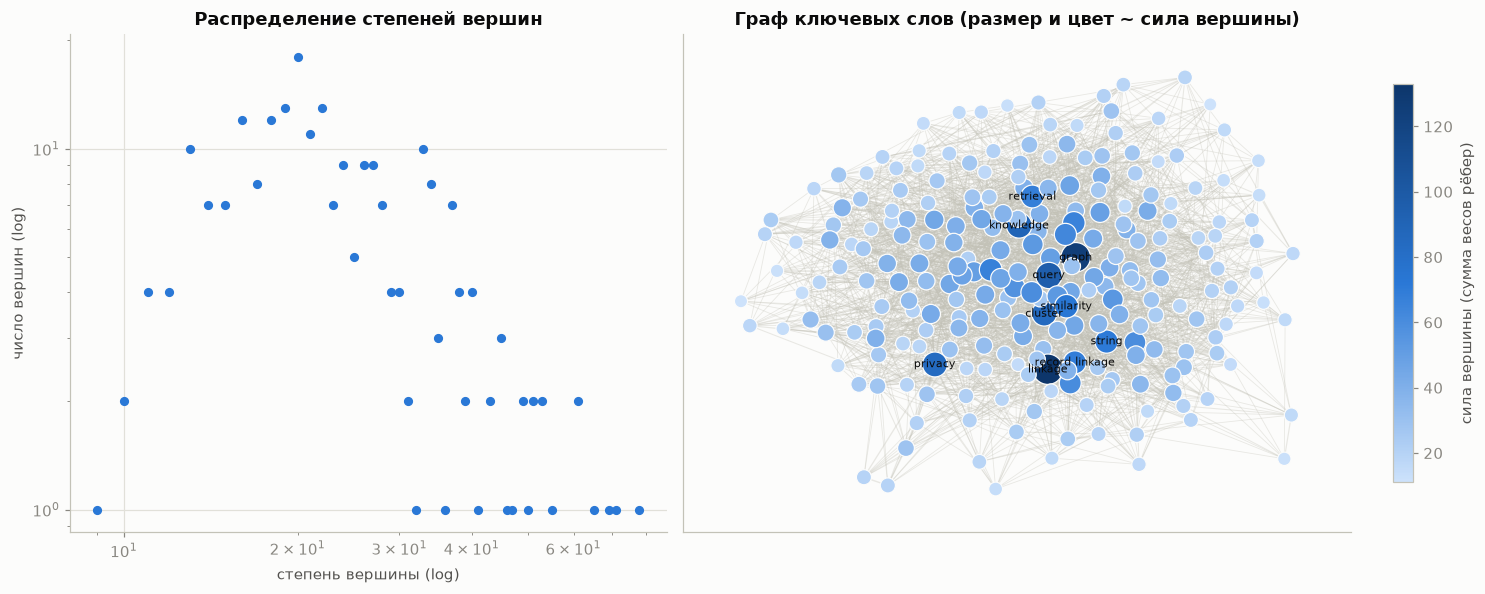

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.4]})

ax = axes[0]
deg_counts = Counter(degree.values())
ds = np.array(sorted(deg_counts))
cs = np.array([deg_counts[d] for d in ds])
ax.loglog(ds, cs, "o", ms=5, color=CAT[0])
ax.set_title("Распределение степеней вершин")
ax.set_xlabel("степень вершины (log)")
ax.set_ylabel("число вершин (log)")

ax = axes[1]
pos = nx.spring_layout(G, seed=RANDOM_STATE, k=1.2 / np.sqrt(G.number_of_nodes()), iterations=60)
node_strength = np.array([strength[n] for n in G.nodes])
node_size = 45 + 350 * node_strength / node_strength.max()
edge_w = np.array([G[u][v]["weight"] for u, v in G.edges()])
nx.draw_networkx_edges(G, pos, ax=ax, edge_color=AXIS, alpha=0.35,
                       width=0.3 + 0.35 * np.log1p(edge_w))
nodes = nx.draw_networkx_nodes(G, pos, ax=ax, node_size=node_size,
                               node_color=node_strength, cmap=SEQ_CMAP,
                               edgecolors="#fcfcfb", linewidths=0.8)
big = sorted(G, key=lambda n: (-strength[n], n))[:10]
nx.draw_networkx_labels(G, pos, ax=ax, labels={n: n for n in big}, font_size=7, font_color=INK)
ax.set_title("Граф ключевых слов (размер и цвет ~ сила вершины)")
ax.grid(False)
plt.colorbar(nodes, ax=ax, label="сила вершины (сумма весов рёбер)", shrink=0.8)
fig.tight_layout()
plt.show()

## Пункт 6. Группы ключевых слов

> Определить кластеры ключевых слов на графе. Оценить качество кластеризации (например, по модулярности). Интерпретировать результат кластеризации, то есть объяснить, какие ключевые слова попали в кластеры и почему.

Алгоритм **Louvain** объединяет слова, между которыми больше связей. Пробуем несколько настроек и выбираем результат с наибольшей **модулярностью** — оценкой того, насколько хорошо слова разделились на связанные внутри себя группы.

Для сравнения используем второй алгоритм и повторяем Louvain с разными начальными условиями. Показатель **ARI** помогает проверить, насколько похожи полученные группы.

In [54]:
from sklearn.metrics import adjusted_rand_score


def get_partition(resolution=1.0, seed=RANDOM_STATE):
    communities = nx_comm.louvain_communities(G, weight="weight", resolution=resolution, seed=seed)
    communities = sorted(communities, key=lambda group: (-len(group), sorted(group)))
    return {node: cluster for cluster, group in enumerate(communities) for node in sorted(group)}


def standard_modularity(partition):
    groups = defaultdict(set)
    for node, cluster in partition.items():
        groups[cluster].add(node)
    return nx_comm.modularity(G, groups.values(), weight="weight", resolution=1)


resolution_partitions = {res: get_partition(res) for res in [0.6, 0.8, 1.0, 1.2, 1.5]}
best_resolution = max(resolution_partitions, key=lambda res: (standard_modularity(resolution_partitions[res]), -abs(res - 1)))
partition = resolution_partitions[best_resolution]
modularity = standard_modularity(partition)
display(pd.DataFrame([
    {"resolution при поиске": res, "кластеров": len(set(p.values())), "Q при resolution=1": standard_modularity(p)}
    for res, p in resolution_partitions.items()
]))
print(f"Выбрано resolution={best_resolution}: {len(set(partition.values()))} кластеров, Q={modularity:.3f}")

greedy_sets = list(nx_comm.greedy_modularity_communities(G, weight="weight"))
print(f"Greedy: {len(greedy_sets)} кластеров, Q={nx_comm.modularity(G, greedy_sets, weight='weight'):.3f}")
seed_partitions = [get_partition(best_resolution, seed) for seed in range(5)]
seed_ari = [adjusted_rand_score([partition[n] for n in G], [p[n] for n in G]) for p in seed_partitions]
print(f"ARI к итоговому разбиению для seed 0–4: {[round(value, 3) for value in seed_ari]}")

,resolution при поиске,кластеров,Q при resolution=1
0,0.6,2,0.173482
1,0.8,5,0.273956
2,1.0,9,0.278646
3,1.2,12,0.280035
4,1.5,16,0.262181


Выбрано resolution=1.2: 12 кластеров, Q=0.280
Greedy: 6 кластеров, Q=0.288
ARI к итоговому разбиению для seed 0–4: [0.543, 0.545, 0.483, 0.368, 0.545]


### Пункт 6. Состав групп

> Определить кластеры ключевых слов на графе. Оценить качество кластеризации (например, по модулярности). Интерпретировать результат кластеризации, то есть объяснить, какие ключевые слова попали в кластеры и почему.

Выводим размер каждой группы и её основные ключевые слова.

In [55]:
clusters = defaultdict(list)
for kw, c in partition.items():
    clusters[c].append(kw)
cluster_order = sorted(clusters, key=lambda c: -len(clusters[c]))

table = []
for rank, c in enumerate(cluster_order, 1):
    kws_sorted = sorted(clusters[c], key=lambda k: -strength[k])
    table.append({"кластер": rank,
                  "размер": len(kws_sorted),
                  "топ-ключевые слова": ", ".join(kws_sorted[:10])})
display(pd.DataFrame(table))

,кластер,размер,топ-ключевые слова
0,1,34,"query, retrieval, search, document, rag, recall, extraction, annotation, column, evidence"
1,2,30,"linkage, record linkage, record, file, link, database, point, attribute, value, survey"
2,3,29,"cost, product, entity matching, llms, pair, prediction, learning, space, example, prompt"
3,4,29,"similarity, string, embedding, rule, architecture, string matching, blocking, candidate, function, length"
4,5,27,"interaction, literature, system, cleaning, data cleaning, discovery, disease, table, resource, health"
5,6,17,"label, llm, integration, mapping, pipeline, gap, benchmark, representation, data integration, matrix"
6,7,16,"encoder, translation, description, match, machine translation, word, fuzzy match, tool, language, recognition"
7,8,15,"training, matcher, domain, metric, training data, alignment, distribution, scenario, distance, distillation"
8,9,13,"cluster, property, decision, clustering, size, class, partition, assumption, random partition, topic"
9,10,12,"privacy, ground truth, pprl, party, entity resolution, latency, protocol, preserving, privacy preserving, ..."


### Пункт 6. Группы на графе

> Определить кластеры ключевых слов на графе. Оценить качество кластеризации (например, по модулярности). Интерпретировать результат кластеризации, то есть объяснить, какие ключевые слова попали в кластеры и почему.

Отмечаем разными цветами найденные группы слов.

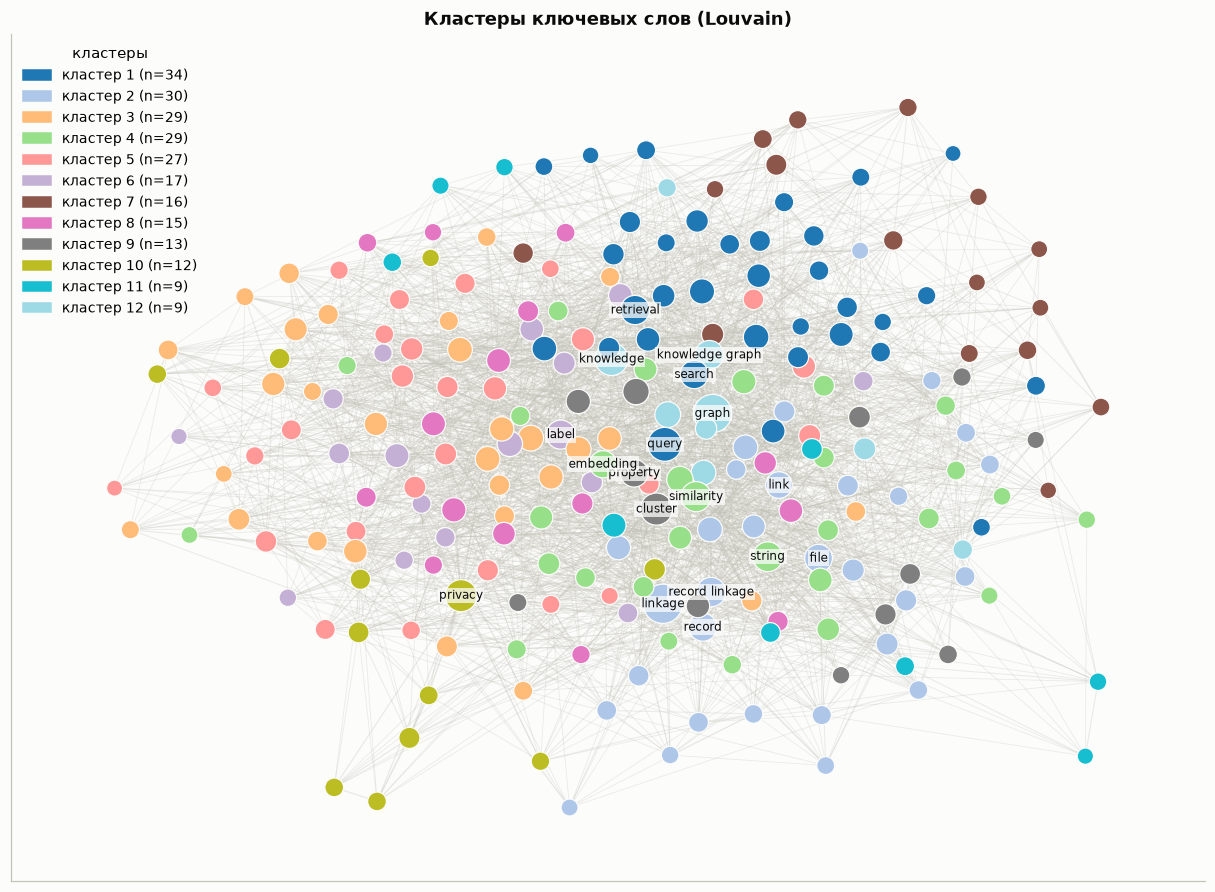

In [56]:
fig, ax = plt.subplots(figsize=(14, 10))
cluster_palette = plt.colormaps["tab20"].resampled(len(cluster_order))
cluster_color = {c: cluster_palette(rank - 1) for rank, c in enumerate(cluster_order, 1)}
node_colors = [cluster_color[partition[n]] for n in G.nodes]

nx.draw_networkx_edges(G, pos, ax=ax, edge_color=AXIS, alpha=0.3,
                       width=0.3 + 0.35 * np.log1p(edge_w))
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=60 + 600 * node_strength / node_strength.max(),
                       node_color=node_colors, edgecolors="#fcfcfb", linewidths=0.8)
big = sorted(G, key=lambda n: (-strength[n], n))[:18]
nx.draw_networkx_labels(G, pos, ax=ax, labels={n: n for n in big}, font_size=8, font_color=INK,
                        bbox={"facecolor": "#fcfcfb", "alpha": 0.75, "edgecolor": "none", "pad": 1})
handles = [mpatches.Patch(color=cluster_color[c],
                          label=f"кластер {r} (n={len(clusters[c])})")
           for r, c in enumerate(cluster_order, 1)]
ax.legend(handles=handles, frameon=False, loc="upper left", fontsize=9, title="кластеры")
ax.set_title("Кластеры ключевых слов (Louvain)")
ax.grid(False)
ax.margins(0.05)
plt.show()

**Вывод по пункту 6:**

1. **Поиск и извлечение информации (34):** `query`, `retrieval`, `search`, `document`, `rag` — поиск документов и извлечение сведений, в том числе с помощью языковых моделей.
2. **Сопоставление записей (30):** `linkage`, `record linkage`, `record`, `file`, `database` — объединение записей из разных файлов и баз данных.
3. **LLM для сопоставления сущностей (29):** `entity matching`, `llms`, `prompt`, `active learning`, `cost` — сопоставление пар записей с помощью языковых моделей и выбор примеров для обучения.
4. **Сравнение строк и отбор кандидатов (29):** `similarity`, `string`, `embedding`, `string matching`, `blocking` — оценка сходства и предварительный отбор записей для сравнения.
5. **Очистка данных и прикладные системы (27):** `system`, `data cleaning`, `table`, `health` — очистка таблиц и работа с данными в приложениях, включая здравоохранение; группа смешанная.
6. **Интеграция и подготовка данных (17):** `label`, `integration`, `mapping`, `pipeline`, `benchmark` — объединение данных, их разметка и проверка методов.
7. **Обработка языка (16):** `translation`, `machine translation`, `fuzzy match`, `language`, `ner` — перевод, распознавание сущностей и нечёткое сопоставление текста.
8. **Обучение и перенос методов (15):** `training`, `matcher`, `domain`, `training data`, `adaptation` — обучение моделей и их применение к другим данным.
9. **Кластеризация (13):** `cluster`, `clustering`, `partition`, `random partition` — разделение записей на группы и выбор разбиения.
10. **Приватное сопоставление (12):** `privacy`, `pprl`, `party`, `protocol`, `privacy preserving` — сопоставление данных нескольких участников с защитой информации.
11. **Нейросети и приложения (9):** `deep learning`, `network`, `neural network`, `address` — нейросетевые методы и их применение, в том числе к адресам.
12. **Графы знаний (9):** `graph`, `knowledge`, `knowledge graph`, `relationship` — представление объектов и связей между ними с помощью графов.

Получено **12 групп**, модулярность **Q = 0.280** при `resolution=1.2`. Второй алгоритм выделил **6 групп**, **Q = 0.288**. При повторных запусках состав групп меняется (ARI **0.368–0.545**), поэтому такое разделение приблизительное.

## Пункт 7. Самые важные слова в графе

> Найти ключевые слова с наибольшими значениями центральности в выбранной тематике (например, degree centrality, betweenness centrality, eigenvector centrality, closeness centrality). Найти не менее трех разных значений центральностей. Интерпретировать результаты.

Сравним четыре показателя центральности:

- **Degree** — со сколькими другими словами связано слово.
- **Betweenness** — как часто через слово проходят кратчайшие пути между другими словами.
- **Eigenvector** — насколько сильно слово связано с другими важными словами.
- **Closeness** — насколько короткие пути ведут от слова к остальным.

Для расчёта путей сильным связям назначаем меньшую длину: `1 / вес`.

In [57]:
for u, v, d in G.edges(data=True):
    d["inv_weight"] = 1.0 / d["weight"]

largest_cc = max(nx.connected_components(G), key=len)
eigen_lcc = nx.eigenvector_centrality_numpy(G.subgraph(largest_cc), weight="weight")
eigenvector_all = {n: eigen_lcc.get(n, 0.0) for n in G.nodes}

centralities = {
    "degree": nx.degree_centrality(G),
    "betweenness": nx.betweenness_centrality(G, weight="inv_weight", normalized=True),
    "eigenvector": eigenvector_all,
    "closeness": nx.closeness_centrality(G, distance="inv_weight", wf_improved=True),
}

cent_df = pd.DataFrame(centralities)
cent_df.insert(0, "keyword", cent_df.index)

for name in ["degree", "betweenness", "eigenvector", "closeness"]:
    top = cent_df.nlargest(10, name)[["keyword", name]].reset_index(drop=True)
    top.index += 1
    display(top)

,keyword,degree
1,graph,0.326360
2,linkage,0.297071
3,query,0.288703
4,cluster,0.271967
5,knowledge,0.255230
6,similarity,0.255230
7,privacy,0.230126
8,label,0.221757
9,retrieval,0.221757
10,embedding,0.213389


,keyword,betweenness
1,graph,0.171732
2,linkage,0.148855
3,query,0.090981
4,knowledge,0.060242
5,privacy,0.052013
6,cluster,0.049067
7,search,0.042076
8,string,0.034070
9,retrieval,0.033297
10,label,0.033249


,keyword,eigenvector
1,graph,0.296610
2,linkage,0.296581
3,knowledge graph,0.219047
4,knowledge,0.217609
5,record linkage,0.203482
6,record,0.169385
7,query,0.166087
8,cluster,0.148428
9,similarity,0.141605
10,file,0.133952


,keyword,closeness
1,graph,0.974298
2,knowledge graph,0.923395
3,knowledge,0.920933
4,query,0.905287
5,linkage,0.888605
6,property,0.854082
7,record linkage,0.841088
8,cluster,0.837130
9,similarity,0.834569
10,search,0.830397


### Пункт 7. Сравнение центральностей

> Найти ключевые слова с наибольшими значениями центральности в выбранной тематике (например, degree centrality, betweenness centrality, eigenvector centrality, closeness centrality). Найти не менее трех разных значений центральностей. Интерпретировать результаты.

Показываем слова с наибольшими значениями четырёх показателей.

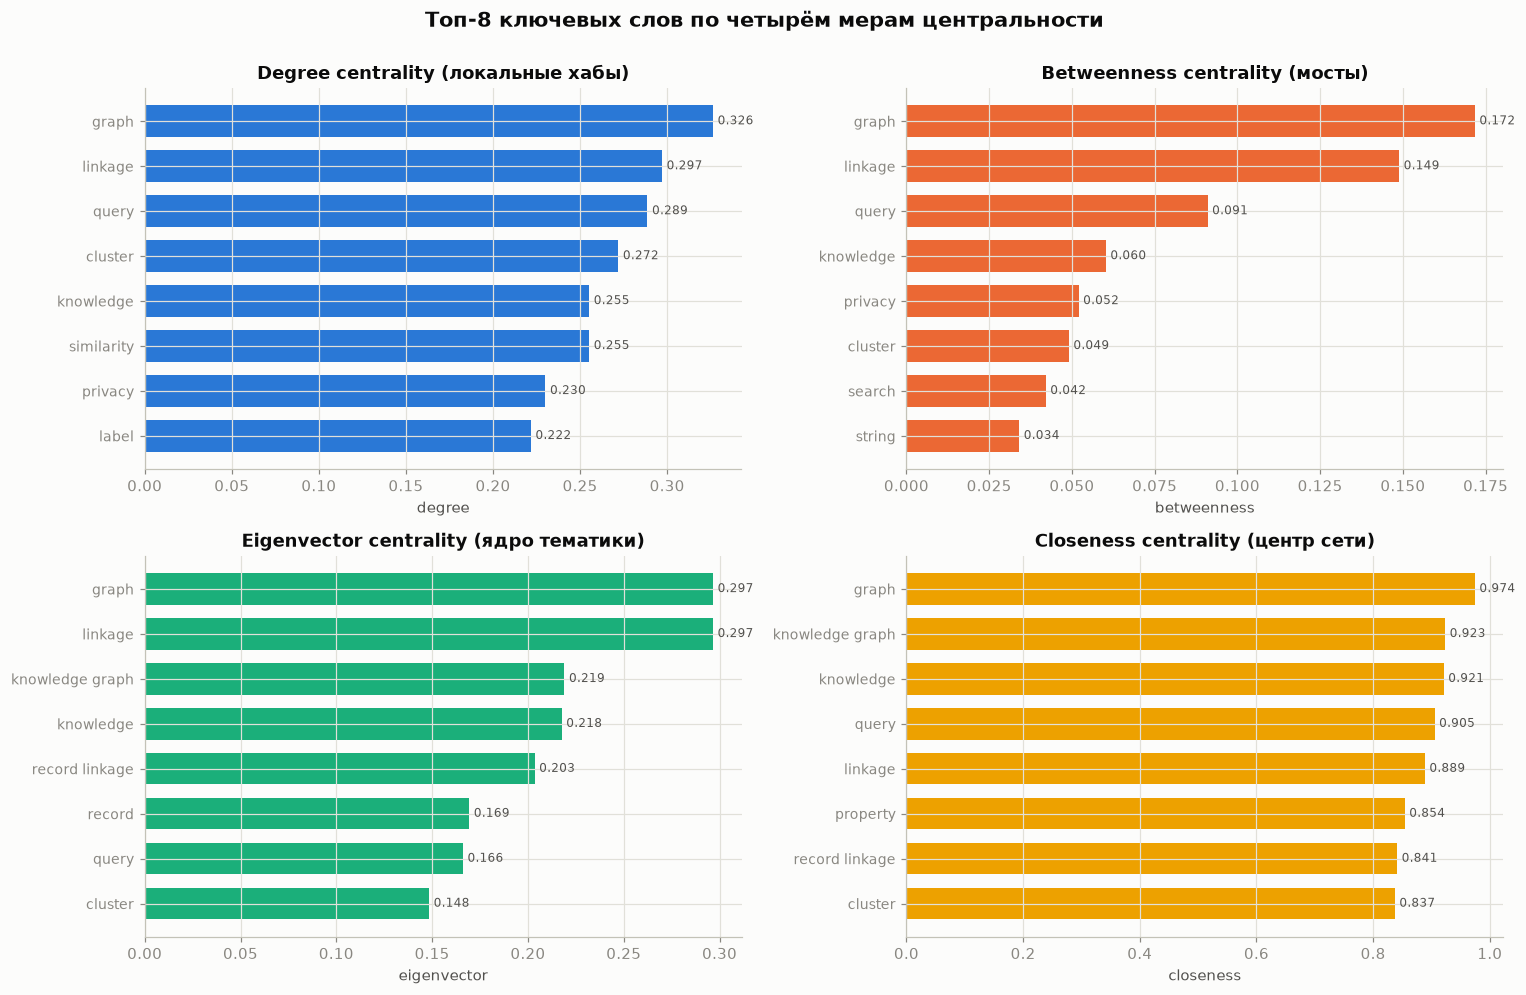

In [58]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
titles = {"degree": "Degree centrality (локальные хабы)",
          "betweenness": "Betweenness centrality (мосты)",
          "eigenvector": "Eigenvector centrality (ядро тематики)",
          "closeness": "Closeness centrality (центр сети)"}
for ax, (name, title) in zip(axes.flat, titles.items()):
    top = cent_df.nlargest(8, name).iloc[::-1]
    ax.barh(top["keyword"], top[name],
            color=CAT[["degree", "betweenness", "eigenvector", "closeness"].index(name)],
            height=0.7)
    ax.bar_label(ax.containers[0], padding=3, fontsize=8, color=INK2, fmt=lambda v: f"{v:.3f}")
    ax.set_title(title)
    ax.set_xlabel(name)
    ax.tick_params(axis="y", labelsize=9)
fig.suptitle("Топ-8 ключевых слов по четырём мерам центральности", fontsize=14,
             fontweight="bold", color=INK, y=1.00)
fig.tight_layout()
plt.show()

**Вывод по пункту 7:**

- **Degree:** `graph` — **0.326**, 78 связанных слов. Оно встречается рядом с терминами разных методов и задач.
- **Betweenness:** `graph` — **0.172**, `linkage` — **0.149**. Через эти слова проходят многие короткие пути между другими словами.
- **Eigenvector:** `graph` и `linkage` — примерно **0.297**. Они тесно связаны с другими важными словами; значения почти одинаковы.
- **Closeness:** `graph` — **0.974**, `knowledge graph` — **0.923**. От них в среднем короче пути до остальных слов с учётом силы связей.

Все четыре показателя выделяют `graph`, но объясняют его роль по-разному. Результаты относятся к нашему набору статей и выбранным ключевым словам.

## Пункт 8. Граф статей

> Построить граф публикаций: если ключевое слово является тегом для двух публикаций, значит, между ними связь есть. Чем больше общих ключевых слов, тем сильнее связь (выше вес ребра). Реализовать поиск наиболее близких к заданной пользователем публикаций на графе.

Каждая точка — статья. Две статьи соединяются, если у них есть хотя бы одно общее ключевое слово. Вес связи равен числу общих слов.

Ищем близкие статьи двумя способами: по числу общих слов (`most_similar`) и по коротким путям через другие статьи (`nearest_by_path`). Во втором случае используем алгоритм Дейкстры; сильные связи считаются более короткими.

In [59]:
MIN_COMMON = 1

kw_sets = [set(kws) for kws in df["keywords"]]
P = nx.Graph()
P.add_nodes_from(range(len(df)))
for i in range(len(df)):
    for j in range(i + 1, len(df)):
        w = len(kw_sets[i] & kw_sets[j])
        if w >= MIN_COMMON:
            P.add_edge(i, j, weight=w)
for u, v, d in P.edges(data=True):
    d["inv_weight"] = 1.0 / d["weight"]

p_strength = dict(P.degree(weight="weight"))
comps = sorted(nx.connected_components(P), key=len, reverse=True)
print(f"Граф публикаций: {P.number_of_nodes()} вершин, {P.number_of_edges()} рёбер")
print(f"Плотность: {nx.density(P):.5f}")
print(f"Компонент связности: {nx.number_connected_components(P)}")
print(f"Размеры крупнейших компонент: {[len(c) for c in comps[:5]]}")
print(f"Изолированных публикаций: {sum(1 for n in P.nodes if P.degree(n) == 0)}")

print("\nСамые тесно связанные пары публикаций:")
for i, j, d in sorted(P.edges(data=True), key=lambda e: -e[2]["weight"])[:5]:
    print(f"  w={d['weight']} | {df.loc[i, 'title'][:60]}")
    print(f"         | {df.loc[j, 'title'][:60]}")

Граф публикаций: 477 вершин, 9453 рёбер
Плотность: 0.08327
Компонент связности: 1
Размеры крупнейших компонент: [477]
Изолированных публикаций: 0

Самые тесно связанные пары публикаций:
  w=7 | Leveraging Subword Embeddings for Multinational Address Pars
         | Multinational Address Parsing: A Zero-Shot Evaluation
  w=7 | GenASM: A High-Performance, Low-Power Approximate String Mat
         | Accelerating Genome Sequence Analysis via Efficient Hardware
  w=7 | GenASM: A High-Performance, Low-Power Approximate String Mat
         | ASMCap: An Approximate String Matching Accelerator for Genom
  w=7 | Accelerating Genome Sequence Analysis via Efficient Hardware
         | ASMCap: An Approximate String Matching Accelerator for Genom
  w=7 | Privacy-Preserving Record Linkage
         | Multi-Layer Privacy-Preserving Record Linkage with Clerical 


### Пункт 8. Рисунок графа статей

> Построить граф публикаций: если ключевое слово является тегом для двух публикаций, значит, между ними связь есть. Чем больше общих ключевых слов, тем сильнее связь (выше вес ребра). Реализовать поиск наиболее близких к заданной пользователем публикаций на графе.

Показываем часть графа статей с наиболее сильными связями.

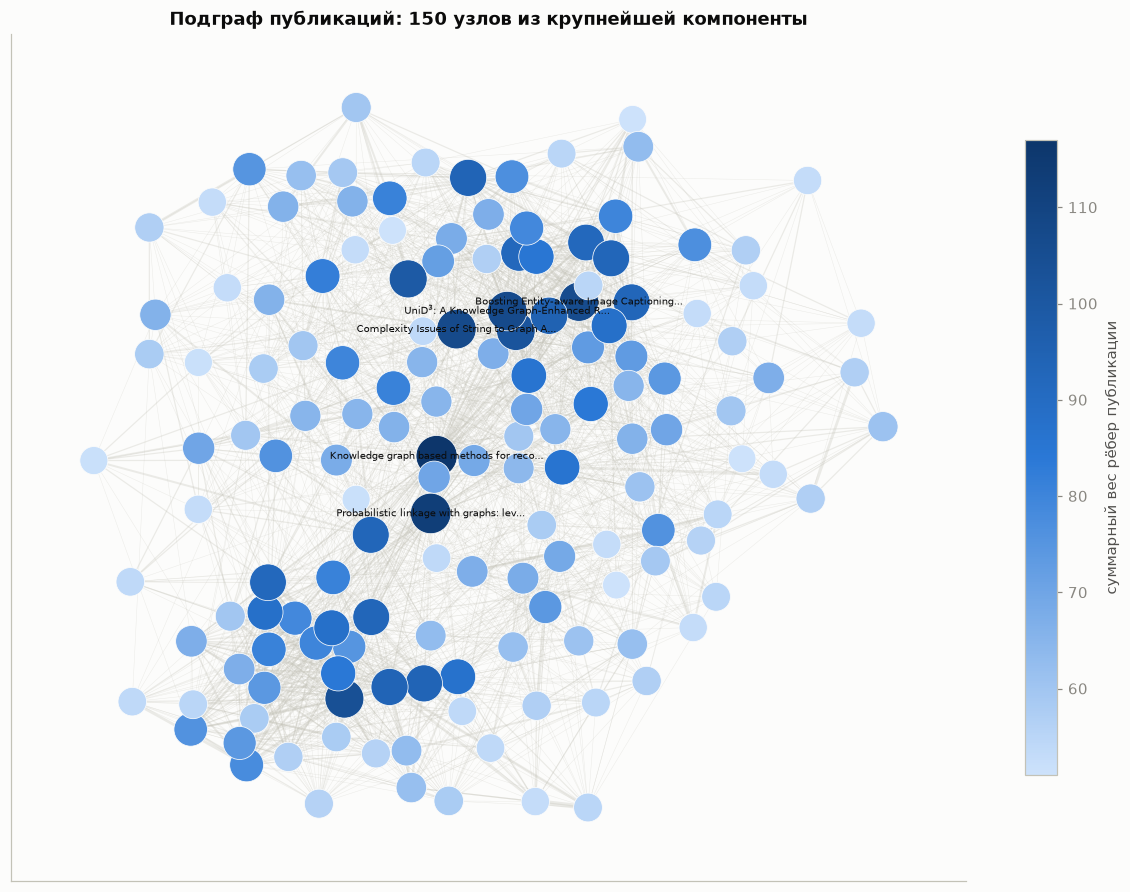

In [60]:
comp = comps[0]
if len(comp) > 150:
    core = sorted(comp, key=lambda n: -p_strength[n])[:150]
    sub = P.subgraph(core)
else:
    sub = P.subgraph(comp)

fig, ax = plt.subplots(figsize=(14, 10))
pos_p = nx.spring_layout(sub, seed=RANDOM_STATE,
                         k=1.5 / np.sqrt(sub.number_of_nodes()), iterations=60)
w_arr = np.array([sub[u][v]["weight"] for u, v in sub.edges()])
nx.draw_networkx_edges(sub, pos_p, ax=ax, edge_color=AXIS, alpha=0.3,
                       width=0.3 + 0.5 * (w_arr - MIN_COMMON))
n_arr = np.array([p_strength[n] for n in sub.nodes()])
nodes = nx.draw_networkx_nodes(sub, pos_p, ax=ax, node_size=25 + 6 * n_arr,
                               node_color=n_arr, cmap=SEQ_CMAP,
                               edgecolors="#fcfcfb", linewidths=0.5)
labels = {n: df.loc[n, "title"][:38] + "..." for n in sub.nodes()
          if p_strength[n] >= np.percentile(n_arr, 97)}
nx.draw_networkx_labels(sub, pos_p, ax=ax, labels=labels, font_size=6.5, font_color=INK)
ax.set_title(f"Подграф публикаций: {sub.number_of_nodes()} узлов из крупнейшей компоненты")
ax.grid(False)
plt.colorbar(nodes, ax=ax, label="суммарный вес рёбер публикации", shrink=0.75)
plt.show()

## Пункт 9. Поиск и проверка

> Реализовать и протестировать поиск публикаций по графу публикаций.

Функция `find_paper` находит исходную статью, а `search_papers` предлагает похожие. Режим `neighbors` ищет по прямым связям, `paths` — по путям через другие статьи.

Если найдено несколько исходных статей, выбирается статья с наибольшей суммой весов связей. Чтобы выбрать конкретную статью, вводим её полный arXiv id.

In [61]:
def validate_k(k):
    if isinstance(k, bool) or not isinstance(k, (int, np.integer)) or k < 0:
        raise ValueError("k должно быть целым неотрицательным числом")


def find_paper(query):
    q = str(query).strip().lower()
    if not q:
        return df.iloc[0:0]
    exact = df["arxiv_id"].str.lower().eq(q) | df["title"].str.lower().eq(q)
    if exact.any():
        return df[exact]
    mask = df["arxiv_id"].str.lower().str.contains(q, regex=False, na=False) | df["title"].str.lower().str.contains(q, regex=False, na=False)
    return df[mask]


def most_similar(paper, k=5, verbose=True):
    validate_k(k)
    if paper not in P:
        if verbose:
            print(f"Вершина {paper!r} отсутствует в графе")
        return []
    neighbors = sorted(P[paper], key=lambda n: (-P[paper][n]["weight"], n))[:k]
    rows = [(n, P[paper][n]["weight"], sorted(kw_sets[paper] & kw_sets[n])) for n in neighbors]
    if verbose:
        print(f"Стартовая публикация [{df.loc[paper, 'arxiv_id']}] {df.loc[paper, 'title']}")
        for n, weight, shared in rows:
            print(f"  w={weight} [{df.loc[n, 'arxiv_id']}] {df.loc[n, 'title']}")
            print("    общие термины:", ", ".join(shared))
        if not rows:
            print("Рекомендаций нет")
    return rows


def nearest_by_path(paper, k=5, verbose=True):
    validate_k(k)
    if paper not in P:
        return []
    distances = nx.single_source_dijkstra_path_length(P, paper, weight="inv_weight")
    nearest = sorted((distance, node) for node, distance in distances.items() if node != paper)[:k]
    rows = [(node, distance, P[paper][node]["weight"] if P.has_edge(paper, node) else None) for distance, node in nearest]
    if verbose:
        print(f"Дейкстра от [{df.loc[paper, 'arxiv_id']}]: {df.loc[paper, 'title']}")
        for node, distance, direct_weight in rows:
            print(f"  d={distance:.3f}, прямой вес={direct_weight}: [{df.loc[node, 'arxiv_id']}] {df.loc[node, 'title']}")
    return rows


def search_papers(query, k=5, mode="neighbors", verbose=True):
    validate_k(k)
    if mode not in {"neighbors", "paths"}:
        raise ValueError("mode должен быть neighbors или paths")
    found = find_paper(query)
    if found.empty:
        if verbose:
            print(f"По запросу {query!r} публикаций не найдено")
        return []
    start = min(found.index, key=lambda n: (-p_strength[n], n))
    if verbose and len(found) > 1:
        print(f"Совпадений: {len(found)}; выбрана статья [{df.loc[start, 'arxiv_id']}] по сумме весов связей")
    search = most_similar if mode == "neighbors" else nearest_by_path
    return search(start, k=k, verbose=verbose)

### Пункт 9. Примеры поиска

> Реализовать и протестировать поиск публикаций по графу публикаций.

Проверяем два режима на разных статьях об адресах:

- `address`: выбираем первую найденную статью и получаем пять рекомендаций по общим тегам (`neighbors`).
- `deepparse`: находим статью об инструменте разбора адресов и получаем пять рекомендаций по кратчайшим путям (`paths`).

In [65]:
address_papers = find_paper("address")
if not address_papers.empty:
    search_papers(address_papers.iloc[0]["arxiv_id"], mode="neighbors", k=5)

deepparse_papers = find_paper("deepparse")
if not deepparse_papers.empty:
    search_papers(deepparse_papers.iloc[0]["arxiv_id"], mode="paths", k=5)

Стартовая публикация [2006.16152] Leveraging Subword Embeddings for Multinational Address Parsing
  w=7 [2112.04008] Multinational Address Parsing: A Zero-Shot Evaluation
    общие термины: address, address parsing, country, multinational, multinational address, neural network, postal code
  w=6 [2311.11846] Deepparse : An Extendable, and Fine-Tunable State-Of-The-Art Library for Parsing Multinational Street Addresses
    общие термины: address, address parsing, country, multinational, multinational address, parsing
  w=2 [2007.05881] Applying recent advances in Visual Question Answering to Record Linkage
    общие термины: network, neural network
  w=2 [2010.11075] Neural Networks for Entity Matching: A Survey
    общие термины: network, neural network
  w=2 [2506.05779] Pegasus: A Universal Framework for Scalable Deep Learning Inference on the Dataplane
    общие термины: network, neural network
Дейкстра от [2311.11846]: Deepparse : An Extendable, and Fine-Tunable State-Of-The-Art Li

**Вывод по пункту 9.** Проверены оба режима поиска на разных статьях об адресах.

- **`neighbors`, статья `2006.16152`.** Первыми найдены Zero-Shot Address Parsing (`2112.04008`, 7 общих тегов) и Deepparse (`2311.11846`, 6 тегов). Обе работы посвящены разбору адресов. Остальные три рекомендации связаны общими тегами `network` и `neural network`, поэтому охватывают более широкие темы.
- **`paths`, Deepparse (`2311.11846`).** Ближе всего оказались статьи об адресном парсинге `2006.16152` и `2112.04008` с расстояниями 0.167 и 0.200. Затем найдена работа о сопоставлении географических объектов (`2401.08537`, расстояние 0.500). Ещё две статьи (`2007.05881` и `2010.11075`, расстояние 0.667) найдены через `2006.16152`: прямого ребра с Deepparse у них нет. В выводе это обозначено как `прямой вес=None`.

Первый режим показывает статьи с общими тегами, второй также находит связи через промежуточные публикации. Оба режима дают близкие по теме результаты, но общие термины и косвенные связи могут приводить к менее точным рекомендациям.

**Итог.** Проанализированы 477 публикаций за 2020–2026 годы. Граф ключевых слов содержит 240 вершин и 3095 рёбер; выделено 12 групп при Q = 0.280. Рассчитаны четыре центральности, по всем лидирует `graph`. Граф статей содержит 477 вершин и 9453 ребра. Поиск проверен на двух примерах: по общим тегам для статьи об адресах и по кратчайшим путям для Deepparse. Найдены как прямые, так и косвенные связи между публикациями. Полезность рекомендаций зависит от выбранных ключевых слов.